In [1]:
# Cell 1: Load dataset and initialize plotting style
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

sns.set_theme(style="whitegrid")

california = fetch_california_housing(as_frame=True)
data = california.frame.copy()

print("Dataset shape:", data.shape)
print("Columns:", list(data.columns))
print(data.head())

Dataset shape: (20640, 9)
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [2]:
# Cell 2: Compute feature correlation matrix
correlation_matrix = data.corr(numeric_only=True)

print("Correlation matrix:")
print(correlation_matrix.round(3))

Correlation matrix:
             MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc        1.000    -0.119     0.327     -0.062       0.005     0.019   
HouseAge     -0.119     1.000    -0.153     -0.078      -0.296     0.013   
AveRooms      0.327    -0.153     1.000      0.848      -0.072    -0.005   
AveBedrms    -0.062    -0.078     0.848      1.000      -0.066    -0.006   
Population    0.005    -0.296    -0.072     -0.066       1.000     0.070   
AveOccup      0.019     0.013    -0.005     -0.006       0.070     1.000   
Latitude     -0.080     0.011     0.106      0.070      -0.109     0.002   
Longitude    -0.015    -0.108    -0.028      0.013       0.100     0.002   
MedHouseVal   0.688     0.106     0.152     -0.047      -0.025    -0.024   

             Latitude  Longitude  MedHouseVal  
MedInc         -0.080     -0.015        0.688  
HouseAge        0.011     -0.108        0.106  
AveRooms        0.106     -0.028        0.152  
AveBedrms       0.070      

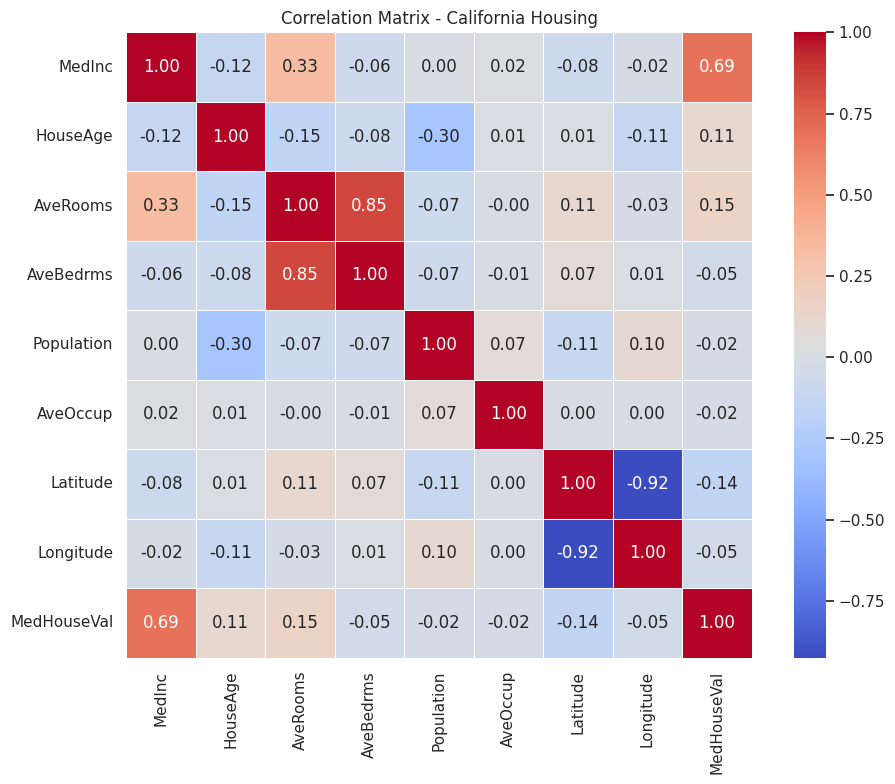

In [3]:
# Cell 3: Visualize correlations using a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True,
)

plt.title("Correlation Matrix - California Housing")
plt.tight_layout()
plt.show()

In [4]:
# Cell 4: Sample rows so pairplot remains fast and readable
sample_size = min(1000, len(data))
sample_data = data.sample(n=sample_size, random_state=42)

print("Pairplot sample size:", sample_data.shape)
print(sample_data.head())

Pairplot sample size: (1000, 9)
       MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
20046  1.6812      25.0  4.192201   1.022284      1392.0  3.877437     36.06   
3024   2.5313      30.0  5.039384   1.193493      1565.0  2.679795     35.14   
15663  3.4801      52.0  3.977155   1.185877      1310.0  1.360332     37.80   
20484  5.7376      17.0  6.163636   1.020202      1705.0  3.444444     34.28   
9814   3.7250      34.0  5.492991   1.028037      1063.0  2.483645     36.62   

       Longitude  MedHouseVal  
20046    -119.01      0.47700  
3024     -119.46      0.45800  
15663    -122.44      5.00001  
20484    -118.72      2.18600  
9814     -121.93      2.78000  


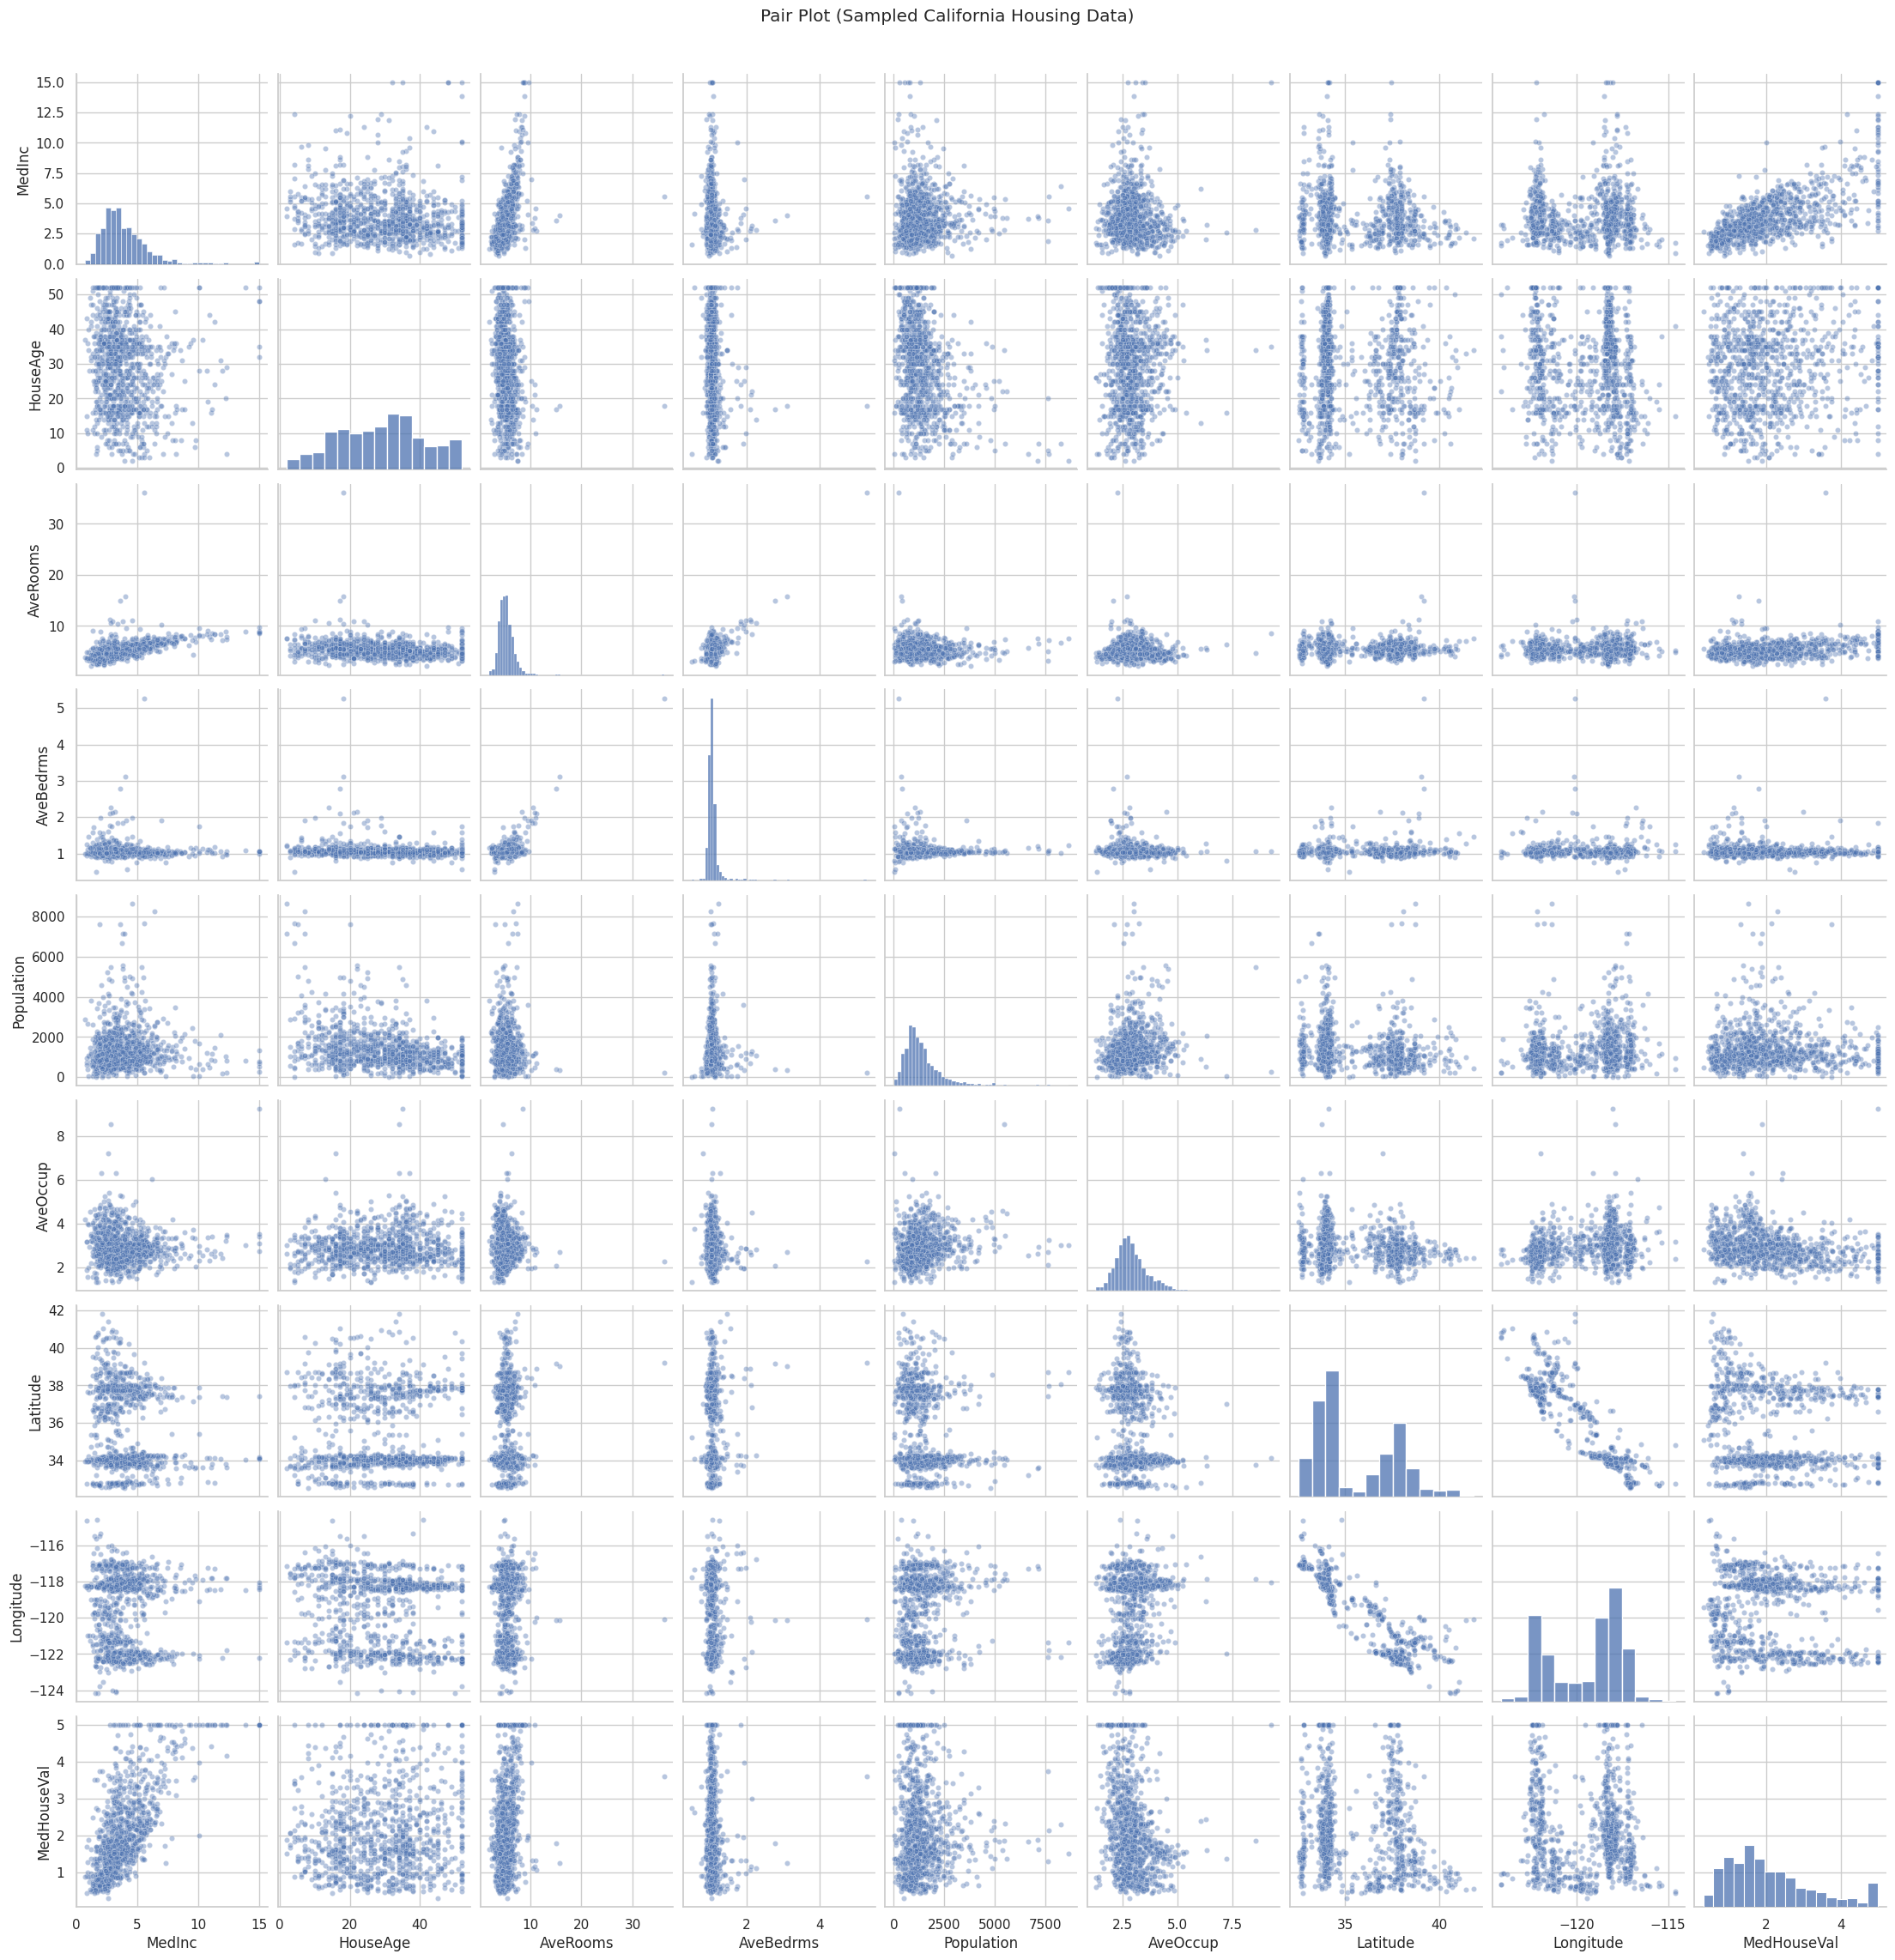

In [5]:
# Cell 5: Pair plot to inspect pairwise feature relationships
pairplot = sns.pairplot(
    sample_data,
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 20},
)

pairplot.fig.suptitle("Pair Plot (Sampled California Housing Data)", y=1.02)
plt.show()

In [6]:
# Cell 6: Rank features by correlation with target (MedHouseVal)
if "MedHouseVal" in correlation_matrix.columns:
    target_corr = correlation_matrix["MedHouseVal"].sort_values(ascending=False)
    print("Feature correlation with MedHouseVal:")
    print(target_corr)
else:
    print("Column MedHouseVal not found in the correlation matrix.")

Feature correlation with MedHouseVal:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64
